# 01 · Data, cleaning and EDA
**Project:** Carrier Advisor, predicting freight cost so the cheapest carrier can be chosen before booking.
Steps: build the SQLite database → check quality with SQL → decide cleaning → explore and test with statistics.

In [1]:
import sys
sys.path.append("..")          # lets the notebook import data.py, predict.py, ...
import json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
warnings.filterwarnings("ignore")
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.figsize": (8, 4)})

from data import build_database, run_query, load_shipments, iqr_upper_fence

## 1 · Build the database
`data.py` loads the CSV into the table `shipments` and creates the view `shipments_clean` (impossible dates set to NULL, 0 kg set to NULL, 0/1 delay flags). Safe to run twice.

In [2]:
build_database()
raw = run_query('SELECT * FROM shipments')
print(raw.shape)
raw.head()

Database ready: /home/claude/lite/logistics-carrier-advisor/data/logistics.db (2,000 shipments)
(2000, 11)


,Shipment_ID,Origin_Warehouse,Destination,Carrier,Shipment_Date,Delivery_Date,Weight_kg,Cost,Status,Distance_miles,Transit_Days
0,SH10000,Warehouse_MIA,San Francisco,UPS,2023-10-02,2023-10-04,25.7,67.46,Delivered,291,2
1,SH10001,Warehouse_MIA,Atlanta,DHL,2023-12-06,2023-12-09,38.9,268.85,Delivered,1225,3
2,SH10002,Warehouse_LA,Houston,DHL,2023-09-18,2023-09-20,37.2,74.35,Delivered,220,2
3,SH10003,Warehouse_BOS,Seattle,OnTrac,2023-01-26,2023-02-04,42.6,187.04,Delivered,1156,9
4,SH10004,Warehouse_SF,Dallas,OnTrac,2023-06-03,2023-06-06,7.9,120.01,Delivered,1017,3


## 2 · Data quality with SQL

In [3]:
run_query("""
SELECT COUNT(*) AS shipments,
       SUM(Cost IS NULL) AS missing_cost,
       SUM(Delivery_Date IS NULL) AS missing_delivery_date,
       SUM(Delivery_Date < Shipment_Date) AS delivered_before_shipped,
       SUM(Weight_kg = 0) AS zero_weight,
       COUNT(*) - COUNT(DISTINCT Shipment_ID) AS duplicate_ids
FROM shipments""")

,shipments,missing_cost,missing_delivery_date,delivered_before_shipped,zero_weight,duplicate_ids
0,2000,41,32,16,1,0


In [4]:
for col in ["Weight_kg", "Cost"]:
    fence = iqr_upper_fence(raw[col].dropna())
    print(f"{col}: 3 x IQR fence = {fence:,.1f}, rows above = {(raw[col] > fence).sum()}, max = {raw[col].max():,.1f}")
raw.sort_values("Cost", ascending=False).head(4)[["Shipment_ID", "Weight_kg", "Distance_miles", "Cost", "Carrier"]]

Weight_kg: 3 x IQR fence = 98.8, rows above = 31, max = 5,404.2
Cost: 3 x IQR fence = 735.3, rows above = 4, max = 6,562.2


,Shipment_ID,Weight_kg,Distance_miles,Cost,Carrier
1105,SH11105,54.6,1942,6562.21,LaserShip
922,SH10922,12.8,2490,6229.12,UPS
1912,SH11912,14.6,2187,1597.99,UPS
1149,SH11149,19.0,870,782.71,USPS


A 12.8 kg parcel costing USD 6,229 and a 5,404 kg shipment costing USD 227 are data-entry errors.

## 3 · Is the data real? Distance on the same lane

In [5]:
spread = raw.groupby(["Origin_Warehouse", "Destination"])["Distance_miles"].std().median()
print(f"Typical distance spread on the same lane: {spread:,.0f} miles")
print(raw[raw["Origin_Warehouse"] == "Warehouse_LA"].query("Destination == 'Los Angeles'")["Distance_miles"].describe()[["count", "min", "max"]])

Typical distance spread on the same lane: 683 miles
count      15.0
min       128.0
max      2499.0
Name: Distance_miles, dtype: float64


**The data is synthetic:** the same lane varies by hundreds of miles and LA → Los Angeles can be over 2,000 miles.
So distance is treated as an **input** the user gives (the app suggests the lane's median).

## 4 · Cleaning decisions
| Issue | Rule |
|---|---|
| Missing Cost (target) | dropped from training |
| Delivery before shipment | date set to NULL in the SQL view (not a model input) |
| Weight = 0 | NULL → median imputation in the pipeline |
| Extreme weight | capped at the 3 × IQR fence |
| Extreme cost (4 rows) | dropped from training |
| Delivery_Date, Status | never used as inputs: they are outcomes (leakage) |

The fences are learned on the 80% training split only (`train.py`), never on the test rows.

## 5 · EDA: what drives cost?

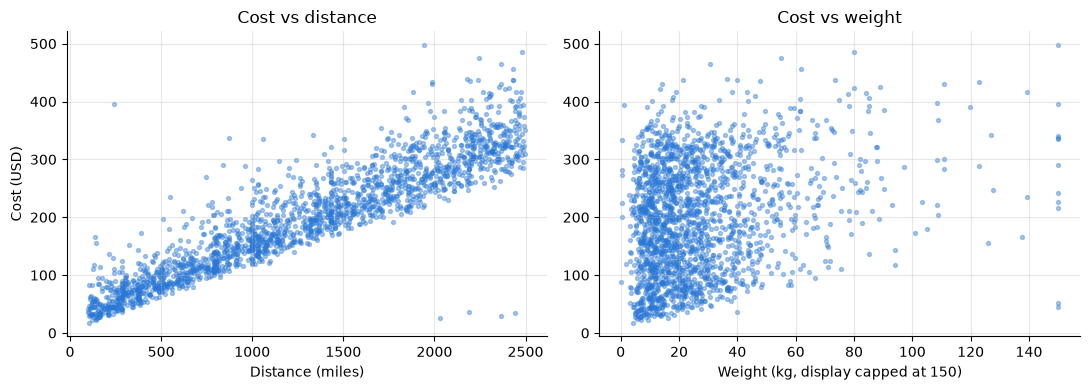

,Cost,Weight_kg,Distance_miles
Cost,1.00,0.22,0.93
Weight_kg,0.22,1.00,0.01
Distance_miles,0.93,0.01,1.00


In [6]:
df = load_shipments()
cost = df[df["Cost"].notna() & (df["Cost"] <= iqr_upper_fence(df["Cost"].dropna()))].copy()
cost["cost_per_mile"] = cost["Cost"] / cost["Distance_miles"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(cost["Distance_miles"], cost["Cost"], s=8, alpha=0.4, color=BLUE)
axes[0].set(xlabel="Distance (miles)", ylabel="Cost (USD)", title="Cost vs distance")
axes[1].scatter(cost["Weight_kg"].clip(upper=150), cost["Cost"], s=8, alpha=0.4, color=BLUE)
axes[1].set(xlabel="Weight (kg, display capped at 150)", title="Cost vs weight")
plt.tight_layout(); plt.show()
cost[["Cost", "Weight_kg", "Distance_miles"]].corr(method="spearman").round(2)

Distance is the main driver (Spearman ρ ≈ 0.93), weight second (ρ ≈ 0.22).

## 6 · Do carriers charge differently? (Kruskal-Wallis)

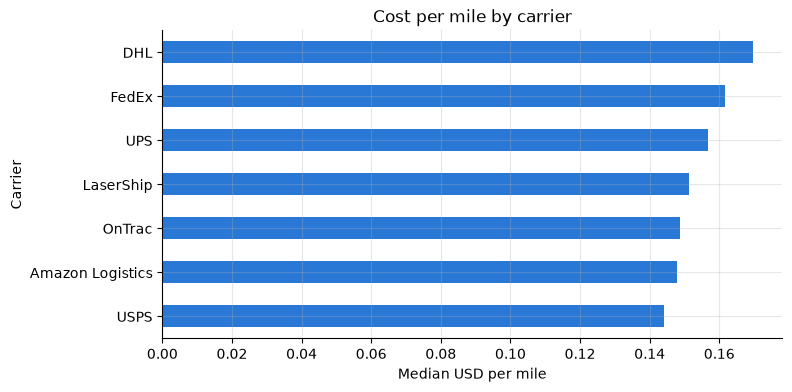

Kruskal-Wallis p-value = 1.6e-29


Carrier
USPS                0.1442
Amazon Logistics    0.1478
OnTrac              0.1487
LaserShip           0.1513
UPS                 0.1567
FedEx               0.1617
DHL                 0.1696
Name: cost_per_mile, dtype: float64

In [7]:
medians = cost.groupby("Carrier")["cost_per_mile"].median().sort_values()
ax = medians.plot.barh(color=BLUE); ax.set(xlabel="Median USD per mile", title="Cost per mile by carrier"); plt.show()
h, p = stats.kruskal(*[g["cost_per_mile"] for _, g in cost.groupby("Carrier")])
print(f"Kruskal-Wallis p-value = {p:.1e}")
medians.round(4)

**Yes (p ≈ 1.6e-29).** USPS ≈ USD 0.144 per mile vs DHL ≈ USD 0.170: about 18% more for the same mile. Carrier choice is a real cost lever.

## 7 · Do carriers differ in reliability? (chi-square)

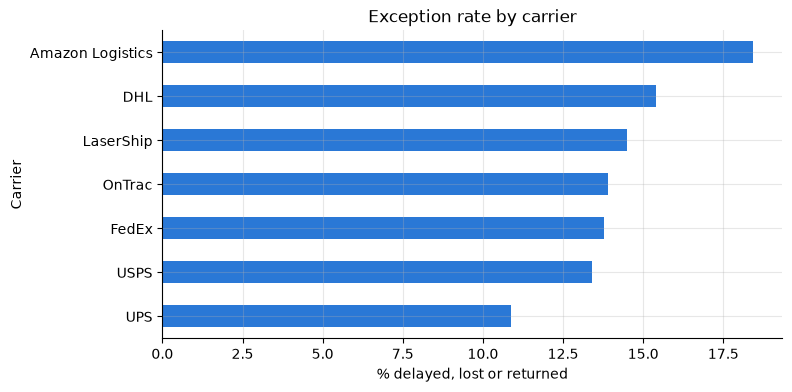

Carrier vs exception, chi-square p = 0.362


Status
Delayed       4.22
Delivered     4.20
In Transit    3.99
Lost          3.80
Returned      3.94
Name: Transit_Days, dtype: float64

In [8]:
done = df[df["Status"] != "In Transit"]
rate = (100 * done.groupby("Carrier")["is_exception"].mean()).sort_values()
ax = rate.plot.barh(color=BLUE); ax.set(xlabel="% delayed, lost or returned", title="Exception rate by carrier"); plt.show()
print("Carrier vs exception, chi-square p =", round(stats.chi2_contingency(pd.crosstab(done["Carrier"], done["is_exception"]))[1], 3))
df.groupby("Status")["Transit_Days"].mean().round(2)

**No (p ≈ 0.36):** the gaps are random noise. Delayed shipments also have the same average transit time (4.2 days) as delivered ones,
so delays are not explained by the data (notebook 02 confirms: a delay classifier scores ROC-AUC ≈ 0.52).

## EDA conclusions
1. Cost ≈ distance + weight + carrier: predictable, so a price model is worth building.
2. Carriers differ by up to about 18% per mile: this is the lever.
3. Reliability differences are not significant: recommend on price, collect better delay data.